# 09 - Phân tích & Trực quan hóa 3 Câu hỏi Nghiên cứu (RQ1, RQ2, RQ3)

Notebook này **chỉ đọc trực tiếp log thô** từ `results/logs/` (không nhập tay số liệu) để phân tích thống kê, kiểm định giả thuyết và vẽ biểu đồ trả lời 3 câu hỏi nghiên cứu mới:

- **RQ1.** *MCTS (gồm cả `MCTS` rollout và `MCTS-leaf` lai) có thể đạt hiệu quả thi đấu tốt hơn Alpha-Beta khi hai tác tử được cấp cùng thời gian suy nghĩ cho mỗi nước đi hay không? Kết quả thay đổi như thế nào khi ngân sách thời gian được điều chỉnh?*
- **RQ2.** *Hàm đánh giá kết hợp yếu tố góc và mobility có mang lại hiệu quả tốt hơn so với hàm đánh giá chỉ dựa trên số lượng quân hay không? Mức độ cải thiện thể hiện như thế nào?*
- **RQ3.** *Tác tử Reinforcement Learning sử dụng phương pháp self-play có cải thiện hiệu quả thi đấu so với tác tử Neural Network được huấn luyện bằng phương pháp supervised learning từ dữ liệu của expert hay không?*

### Đầu ra sinh tự động:
- Biểu đồ lưu tại `results/figures/`:
  - `rq1_mcts_vs_alphabeta.png`
  - `rq2_eval_corners_mobility_vs_discs.png`
  - `rq3_rl_vs_nn.png`
  - `rq_summary_overview.png`
- Bảng số liệu CSV lưu tại `results/tables/research_questions/`.

In [11]:
import json
import math
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))
from eval.metrics import wilson_interval

LOGS = Path(os.environ.get("LOGS_DIR", REPO / "results" / "logs"))
FIGS = Path(os.environ.get("FIG_DIR", REPO / "results" / "figures"))
TABLES = REPO / "results" / "tables" / "research_questions"
FIGS.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

# Tự động chọn bản giải đấu và ablation mới nhất có trên đĩa (có thể ghi đè qua biến môi trường)
def pick_existing(env_key: str, candidates: list[str]) -> Path:
    if os.environ.get(env_key):
        return LOGS / os.environ[env_key]
    for name in candidates:
        p = LOGS / name
        if p.exists():
            return p
    raise FileNotFoundError(f"Không tìm thấy thư mục log nào trong {candidates} tại {LOGS}")

TOURN_DIR = pick_existing("RUN_NAME", ["round_robin_v4", "round_robin_v3", "round_robin_v2", "round_robin_v1"])
ABL_DIR = pick_existing("ABL_DIR", ["ablations_v2", "ablations"])
SWEEP_PATH = LOGS / "rq1_time_budget_sweep" / "summary.json"
MCTS_LEAF_EXTRA_PATH = LOGS / "rq1_mcts_leaf" / "summary.json"

with open(TOURN_DIR / "summary.json", encoding="utf-8") as f:
    tourn = json.load(f)
with open(ABL_DIR / "heuristic_components" / "summary.json", encoding="utf-8") as f:
    abl_heur = json.load(f)
with open(ABL_DIR / "mcts_simulations" / "summary.json", encoding="utf-8") as f:
    abl_mcts = json.load(f)
with open(ABL_DIR / "alphabeta_pruning" / "summary.json", encoding="utf-8") as f:
    abl_prune = json.load(f)

mcts_leaf_extra = json.load(open(MCTS_LEAF_EXTRA_PATH, encoding="utf-8")) if MCTS_LEAF_EXTRA_PATH.exists() else None

LABELS = {
    "random": "Random (C1)",
    "heuristic": "Heuristic (C2)",
    "alphabeta": "Alpha-Beta (C3)",
    "mcts": "MCTS (C4)",
    "mcts_leaf": "MCTS-leaf (C4b)",
    "nn": "NN Supervised (C5)",
    "rl": "RL Self-Play (C6)",
    "alphabeta_discs_only": "Alpha-Beta (Discs Only)",
    "heuristic_discs_only": "Heuristic (Discs Only)",
}

# Thiết lập style chung cho toàn bộ biểu đồ
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

def two_sided_z_pvalue(score: float, n: int, p0: float = 0.5) -> float:
    '''Kiểm định z hai phía cho giả thuyết H0: Score = p0.'''
    if n <= 0:
        return float("nan")
    se = math.sqrt(p0 * (1.0 - p0) / n)
    z = (score - p0) / se
    return math.erfc(abs(z) / math.sqrt(2.0))

def get_pair_record(mode_data: dict, agent_x: str, agent_y: str) -> dict | None:
    '''Trả về thống kê đối đầu theo góc nhìn của agent_x trước agent_y.'''
    for m in mode_data["matches"]:
        if m["a"] == agent_x and m["b"] == agent_y:
            s = m["a_summary"]
            return {
                "x": agent_x, "y": agent_y,
                "games": s["games"], "wins": s["wins"], "draws": s["draws"], "losses": s["losses"],
                "score": s["score"],
                "wilson_ci": tuple(s["score_ci"]),
                "boot_ci": tuple(m["a_score_bootstrap_ci"]),
                "score_black": m["a_as_black"]["score"],
                "score_white": m["a_as_white"]["score"],
                "lat_x": m["latency"][agent_x], "lat_y": m["latency"][agent_y],
                "cost_x": m["cost"][agent_x], "cost_y": m["cost"][agent_y],
            }
        if m["a"] == agent_y and m["b"] == agent_x:
            s = m["a_summary"]
            w, d, l, g = s["losses"], s["draws"], s["wins"], s["games"]
            sc = 1.0 - s["score"]
            lo_w, hi_w = wilson_interval(w + 0.5 * d, g)
            b_lo, b_hi = m["a_score_bootstrap_ci"]
            return {
                "x": agent_x, "y": agent_y,
                "games": g, "wins": w, "draws": d, "losses": l,
                "score": sc,
                "wilson_ci": (lo_w, hi_w),
                "boot_ci": (1.0 - b_hi, 1.0 - b_lo),
                "score_black": 1.0 - m["a_as_white"]["score"],
                "score_white": 1.0 - m["a_as_black"]["score"],
                "lat_x": m["latency"][agent_x], "lat_y": m["latency"][agent_y],
                "cost_x": m["cost"][agent_x], "cost_y": m["cost"][agent_y],
            }
    return None

has_mcts_leaf = ("mcts_leaf" in tourn["config"]["agents"]) or (mcts_leaf_extra is not None)
print(f"Tournament log : {TOURN_DIR.name} ({tourn['meta']['total_games']:,} ván, agents={tourn['config']['agents']})")
print(f"MCTS-leaf data : {'CÓ trong ' + TOURN_DIR.name if 'mcts_leaf' in tourn['config']['agents'] else ('CÓ từ rq1_mcts_leaf' if mcts_leaf_extra else 'CHƯA CÓ — đặt RUN_NAME=round_robin_v4 hoặc bật RUN_RQ1_MCTS_LEAF=True')}")
print(f"Ablation dir   : {ABL_DIR.name}")
print(f"  - alphabeta_pruning    : {abl_prune['meta']['total_games']:,} ván")
print(f"  - mcts_simulations     : {abl_mcts['meta']['total_games']:,} ván")
print(f"  - heuristic_components : {abl_heur['meta']['total_games']:,} ván")
print(f"RQ1 time sweep : {'CÓ (' + str(SWEEP_PATH) + ')' if SWEEP_PATH.exists() else 'CHƯA CHẠY (có cell tùy chọn ở mục 1.2)'}")

Tournament log : round_robin_v3 (8,400 ván, agents=['random', 'heuristic', 'alphabeta', 'mcts', 'mcts_leaf', 'nn', 'rl'])
MCTS-leaf data : CÓ trong round_robin_v3
Ablation dir   : ablations_v2
  - alphabeta_pruning    : 400 ván
  - mcts_simulations     : 1,200 ván
  - heuristic_components : 1,200 ván
RQ1 time sweep : CHƯA CHẠY (có cell tùy chọn ở mục 1.2)


---
## 1. RQ1 — MCTS & MCTS-leaf vs Alpha-Beta dưới cùng thời gian suy nghĩ và khi điều chỉnh ngân sách thời gian

> **RQ1.** *MCTS có thể đạt hiệu quả thi đấu tốt hơn Alpha-Beta khi hai tác tử được cấp cùng thời gian suy nghĩ cho mỗi nước đi hay không? Kết quả thay đổi như thế nào khi ngân sách thời gian được điều chỉnh?*

Phân tích bao quát **cả hai biến thể MCTS**:
- **`MCTS (C4)`**: MCTS thuần dùng rollout heuristic.
- **`MCTS-leaf (C4b)`**: MCTS lai thay rollout bằng hàm lượng giá nút lá của Alpha-Beta qua `sigmoid(score / K)` (nhanh hơn rollout ~10×).

Phân tích gồm 2 phần:
1. **Đối đầu trực tiếp từ giải đấu chính** (`round_robin_v4` hoặc bổ sung từ `rq1_mcts_leaf`): So sánh `MCTS` vs `Alpha-Beta`, `MCTS-leaf` vs `Alpha-Beta`, và `MCTS-leaf` vs `MCTS` ở cả `time_per_move (0.5s)` và `default_config`.
2. **Độ nhạy theo ngân sách thời gian**:
   - Cell tùy chọn chạy quét nhiều mốc `time_budget` (`0.05s, 0.10s, 0.25s, 0.50s, 1.00s`) cho cả 3 tác tử `["alphabeta", "mcts", "mcts_leaf"]`.
   - Đối chiếu với đường cong chi phí thời gian – sức mạnh của MCTS từ `ablations_v2/mcts_simulations`.

In [12]:
# [TÙY CHỌN 1] Nếu giải đấu hiện tại (vd: round_robin_v2) chưa có mcts_leaf,
# bật RUN_RQ1_MCTS_LEAF = True để chạy bổ sung cặp (alphabeta, mcts, mcts_leaf) ở 2 chế độ (time_per_move 0.5s & default_config).
RUN_RQ1_MCTS_LEAF = True
MCTS_LEAF_GAMES = 200   # 200 ván/cặp để đồng bộ chuẩn giải đấu chính

# [TÙY CHỌN 2] Bật RUN_RQ1_SWEEP = True để quét nhiều mốc ngân sách thời gian (0.05s -> 1.0s)
# cho cả 3 tác tử: alphabeta, mcts và mcts_leaf.
RUN_RQ1_SWEEP = False
SWEEP_BUDGETS = [0.05, 0.1, 0.25, 0.5, 1.0]
SWEEP_GAMES_PER_BUDGET = 40   # số chẵn; gợi ý 40-100 ván/mốc (chia đều Đen/Trắng)
SWEEP_WORKERS = 5

if RUN_RQ1_MCTS_LEAF and not has_mcts_leaf:
    from eval.tournament import load_yaml, run_round_robin
    base_cfg = load_yaml(REPO / "configs" / "tournament.yaml")
    specs = load_yaml(REPO / "configs" / "agents.yaml")["agents"]
    leaf_cfg = dict(base_cfg)
    leaf_cfg["run_name"] = "rq1_mcts_leaf"
    leaf_cfg["agents"] = ["alphabeta", "mcts", "mcts_leaf"]
    leaf_cfg["games_per_pair"] = MCTS_LEAF_GAMES
    mcts_leaf_extra = run_round_robin(leaf_cfg, specs, MCTS_LEAF_EXTRA_PATH.parent, workers=SWEEP_WORKERS, verbose=True)
    has_mcts_leaf = True

if RUN_RQ1_SWEEP and not SWEEP_PATH.exists():
    from eval.tournament import load_yaml, run_round_robin
    base_cfg = load_yaml(REPO / "configs" / "tournament.yaml")
    specs = load_yaml(REPO / "configs" / "agents.yaml")["agents"]
    sweep_cfg = dict(base_cfg)
    sweep_cfg["run_name"] = "rq1_time_budget_sweep"
    sweep_cfg["agents"] = ["alphabeta", "mcts", "mcts_leaf"]
    sweep_cfg["games_per_pair"] = SWEEP_GAMES_PER_BUDGET
    sweep_cfg["modes"] = [{"name": f"budget_{b}s", "time_budget": b} for b in SWEEP_BUDGETS]
    run_round_robin(sweep_cfg, specs, SWEEP_PATH.parent, workers=SWEEP_WORKERS, verbose=True)

rq1_sweep = json.load(open(SWEEP_PATH, encoding="utf-8")) if SWEEP_PATH.exists() else None
print("Trạng thái MCTS-leaf       :", "Đã có dữ liệu" if has_mcts_leaf else "Chưa có (bật RUN_RQ1_MCTS_LEAF=True hoặc tải round_robin_v4)")
print("Trạng thái time-budget sweep:", "Đã tải" if rq1_sweep else "Chưa có — dùng đối chiếu 2 chế độ giải đấu + MCTS simulations ablation.")

Trạng thái MCTS-leaf       : Đã có dữ liệu
Trạng thái time-budget sweep: Chưa có — dùng đối chiếu 2 chế độ giải đấu + MCTS simulations ablation.


In [13]:
# 1.1 Bảng đối đầu trực tiếp: MCTS vs Alpha-Beta, MCTS-leaf vs Alpha-Beta (và MCTS-leaf vs MCTS nếu có)
def _find_rq1_pair(mode_name: str, agent_x: str, agent_y: str):
    rec = get_pair_record(tourn["modes"][mode_name], agent_x, agent_y) if mode_name in tourn["modes"] else None
    if rec is None and mcts_leaf_extra is not None and mode_name in mcts_leaf_extra["modes"]:
        rec = get_pair_record(mcts_leaf_extra["modes"][mode_name], agent_x, agent_y)
    return rec

rq1_opponents = ["mcts", "mcts_leaf"] if has_mcts_leaf else ["mcts"]
rq1_rows = []
rq1_leaf_vs_mcts_rows = []

for mode_name in ("time_per_move", "default_config"):
    mdata = tourn["modes"][mode_name]
    budget_label = f"{mdata['time_budget']}s/nước" if mdata["time_budget"] is not None else "default_config"
    for mcts_key in rq1_opponents:
        rec = _find_rq1_pair(mode_name, mcts_key, "alphabeta")
        if rec is None:
            continue
        pval = two_sided_z_pvalue(rec["score"], rec["games"])
        rq1_rows.append({
            "Chế độ": mode_name,
            "Ngân sách": budget_label,
            "Đối đầu (X vs Y)": f"{LABELS[mcts_key]} vs {LABELS['alphabeta']}",
            "mcts_key": mcts_key,
            "W - D - L (MCTS)": f"{rec['wins']} - {rec['draws']} - {rec['losses']}",
            "Score MCTS": round(rec["score"], 4),
            "Score Alpha-Beta": round(1.0 - rec["score"], 4),
            "Bootstrap 95% CI (MCTS)": f"[{rec['boot_ci'][0]:.3f}, {rec['boot_ci'][1]:.3f}]",
            "ci_lo": rec["boot_ci"][0],
            "ci_hi": rec["boot_ci"][1],
            "p-value (H0=0.5)": f"{pval:.2e}" if pval < 1e-3 else f"{pval:.4f}",
            "MCTS Mean (ms)": round(rec["lat_x"]["mean_ms"], 1),
            "AB Mean (ms)": round(rec["lat_y"]["mean_ms"], 1),
            "MCTS Sims/nước": round(rec["cost_x"]["simulations_mean"], 1),
            "AB Nodes/nước": round(rec["cost_y"]["nodes_mean"], 1),
            "MCTS Black": round(rec["score_black"], 3),
            "MCTS White": round(rec["score_white"], 3),
        })
    if has_mcts_leaf:
        rec_lm = _find_rq1_pair(mode_name, "mcts_leaf", "mcts")
        if rec_lm is not None:
            pval_lm = two_sided_z_pvalue(rec_lm["score"], rec_lm["games"])
            rq1_leaf_vs_mcts_rows.append({
                "Chế độ": mode_name,
                "Ngân sách": budget_label,
                "Đối đầu": "MCTS-leaf (C4b) vs MCTS (C4)",
                "W - D - L (MCTS-leaf)": f"{rec_lm['wins']} - {rec_lm['draws']} - {rec_lm['losses']}",
                "Score MCTS-leaf": round(rec_lm["score"], 4),
                "Bootstrap 95% CI": f"[{rec_lm['boot_ci'][0]:.3f}, {rec_lm['boot_ci'][1]:.3f}]",
                "p-value (H0=0.5)": f"{pval_lm:.2e}" if pval_lm < 1e-3 else f"{pval_lm:.4f}",
                "MCTS-leaf Sims/nước": round(rec_lm["cost_x"]["simulations_mean"], 1),
                "MCTS Sims/nước": round(rec_lm["cost_y"]["simulations_mean"], 1),
            })

df_rq1 = pd.DataFrame(rq1_rows)
print("=== BẢNG RQ1a: ĐỐI ĐẦU TRỰC TIẾP MCTS & MCTS-LEAF vs ALPHA-BETA ===")
display(df_rq1.drop(columns=["mcts_key", "ci_lo", "ci_hi"]))
df_rq1.drop(columns=["mcts_key", "ci_lo", "ci_hi"]).to_csv(TABLES / "rq1_mcts_vs_alphabeta.csv", index=False, encoding="utf-8-sig")

if rq1_leaf_vs_mcts_rows:
    df_rq1_lm = pd.DataFrame(rq1_leaf_vs_mcts_rows)
    print("\n=== BẢNG RQ1b: SO SÁNH NỘI BỘ MCTS-LEAF (LAI) vs MCTS (ROLLOUT) ===")
    display(df_rq1_lm)
    df_rq1_lm.to_csv(TABLES / "rq1_mcts_leaf_vs_mcts.csv", index=False, encoding="utf-8-sig")

# 1.2 Dữ liệu độ nhạy ngân sách thời gian / số mô phỏng MCTS
sim_map = {"mcts_100": 100, "mcts_500": 500, "mcts_1000": 1000, "mcts": 2000, "mcts_5000": 5000}
mcts_def = abl_mcts["modes"]["default_config"]
mcts_sens_rows = []
for ag in abl_mcts["config"]["agents"]:
    w, d, l, g = 0, 0, 0, 0
    ms_list, sims_list = [], []
    for m in mcts_def["matches"]:
        if m["a"] == ag or m["b"] == ag:
            is_a = (m["a"] == ag)
            s = m["a_summary"]
            w += s["wins"] if is_a else s["losses"]
            d += s["draws"]
            l += s["losses"] if is_a else s["wins"]
            g += s["games"]
            ms_list.append(m["latency"][ag]["mean_ms"])
            sims_list.append(m["cost"][ag]["simulations_mean"])
    lo, hi = wilson_interval(w + 0.5 * d, g)
    mcts_sens_rows.append({
        "Agent": ag,
        "Configured Sims": sim_map.get(ag, 1000),
        "Actual Sims": round(float(np.mean(sims_list)), 1),
        "Mean Latency (ms)": round(float(np.mean(ms_list)), 2),
        "Mean Score": round(mcts_def["mean_score"][ag], 4),
        "ci_lo": lo, "ci_hi": hi,
    })
df_mcts_sens = pd.DataFrame(mcts_sens_rows).sort_values("Configured Sims").reset_index(drop=True)

df_rq1_sweep = None
if rq1_sweep is not None:
    sw_rows = []
    sweep_mcts_keys = [a for a in ("mcts", "mcts_leaf") if a in rq1_sweep["config"]["agents"]]
    for mname, mdata in rq1_sweep["modes"].items():
        for mk in sweep_mcts_keys:
            rec = get_pair_record(mdata, mk, "alphabeta")
            if rec is None:
                continue
            sw_rows.append({
                "Mode": mname,
                "Agent": mk,
                "Time Budget (s)": mdata["time_budget"],
                "W - D - L (MCTS)": f"{rec['wins']} - {rec['draws']} - {rec['losses']}",
                "Score MCTS": round(rec["score"], 4),
                "Score Alpha-Beta": round(1.0 - rec["score"], 4),
                "ci_lo": rec["boot_ci"][0], "ci_hi": rec["boot_ci"][1],
                "MCTS Sims/nước": round(rec["cost_x"]["simulations_mean"], 1),
                "AB Nodes/nước": round(rec["cost_y"]["nodes_mean"], 1),
            })
    df_rq1_sweep = pd.DataFrame(sw_rows).sort_values(["Agent", "Time Budget (s)"]).reset_index(drop=True)
    print("\n=== BẢNG RQ1c: ĐỘ NHẠY THEO NGÂN SÁCH THỜI GIAN (TIME-BUDGET SWEEP) ===")
    display(df_rq1_sweep)
    df_rq1_sweep.to_csv(TABLES / "rq1_time_budget_sweep.csv", index=False, encoding="utf-8-sig")

=== BẢNG RQ1a: ĐỐI ĐẦU TRỰC TIẾP MCTS & MCTS-LEAF vs ALPHA-BETA ===


,Chế độ,Ngân sách,Đối đầu (X vs Y),W - D - L (MCTS),Score MCTS,Score Alpha-Beta,Bootstrap 95% CI (MCTS),p-value (H0=0.5),MCTS Mean (ms),AB Mean (ms),MCTS Sims/nước,AB Nodes/nước,MCTS Black,MCTS White
0,time_per_move,0.5s/nước,MCTS (C4) vs Alpha-Beta (C3),5 - 0 - 195,0.0250,0.9750,"[0.005, 0.045]",3.77e-41,366.9,388.3,2012.2,19073.0,0.020,0.030
1,time_per_move,0.5s/nước,MCTS-leaf (C4b) vs Alpha-Beta (C3),34 - 5 - 161,0.1825,0.8175,"[0.130, 0.238]",2.70e-19,435.7,389.5,12650.4,18962.6,0.160,0.205
2,default_config,default_config,MCTS (C4) vs Alpha-Beta (C3),22 - 4 - 174,0.1200,0.8800,"[0.075, 0.172]",6.05e-27,664.3,17.0,1654.9,837.0,0.115,0.125
3,default_config,default_config,MCTS-leaf (C4b) vs Alpha-Beta (C3),43 - 1 - 156,0.2175,0.7825,"[0.162, 0.270]",1.35e-15,43.0,19.6,916.3,931.1,0.195,0.240



=== BẢNG RQ1b: SO SÁNH NỘI BỘ MCTS-LEAF (LAI) vs MCTS (ROLLOUT) ===


,Chế độ,Ngân sách,Đối đầu,W - D - L (MCTS-leaf),Score MCTS-leaf,Bootstrap 95% CI,p-value (H0=0.5),MCTS-leaf Sims/nước,MCTS Sims/nước
0,time_per_move,0.5s/nước,MCTS-leaf (C4b) vs MCTS (C4),153 - 2 - 45,0.7700,"[0.708, 0.825]",2.23e-14,19019.1,3176.1
1,default_config,default_config,MCTS-leaf (C4b) vs MCTS (C4),121 - 5 - 74,0.6175,"[0.557, 0.680]",8.89e-04,970.0,1859.7


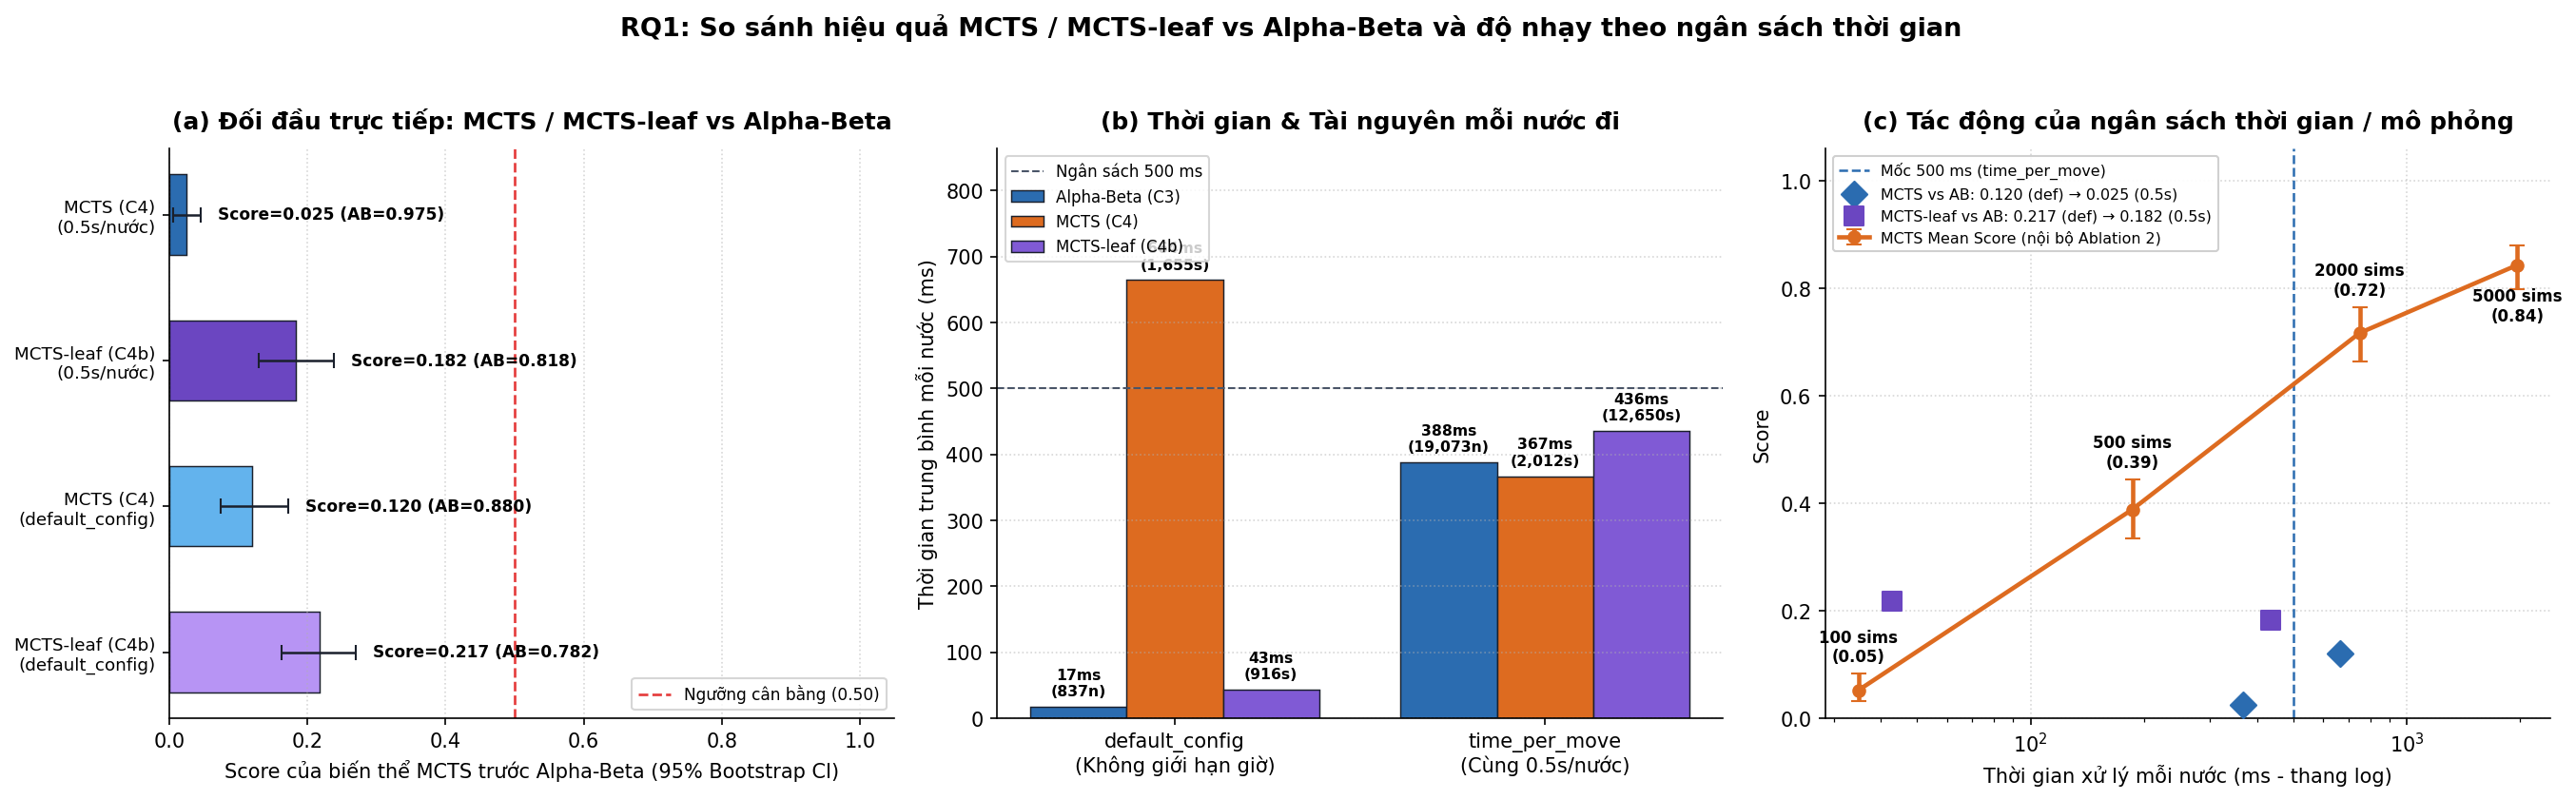

Đã lưu hình: d:\Learn\TTNTNC\Advanced_Artificial_Intelligience_Group\Project_final\results\figures\rq1_mcts_vs_alphabeta.png


In [14]:
# Vẽ biểu đồ RQ1 (3 biểu đồ con: Đối đầu trực tiếp | Thời gian & Chi phí | Độ nhạy theo ngân sách thời gian)
fig, axes = plt.subplots(1, 3, figsize=(18.2, 5.4), dpi=150)

# --- Panel A: Đối đầu trực tiếp MCTS & MCTS-leaf vs Alpha-Beta ---
ax = axes[0]
y_pos = np.arange(len(df_rq1))
vals = df_rq1["Score MCTS"].values
elos = np.maximum(0, vals - df_rq1["ci_lo"].values)
ehis = np.maximum(0, df_rq1["ci_hi"].values - vals)

color_map = {
    ("mcts", "time_per_move"): "#2b6cb0",
    ("mcts", "default_config"): "#63b3ed",
    ("mcts_leaf", "time_per_move"): "#6b46c1",
    ("mcts_leaf", "default_config"): "#b794f4",
}
colors = [color_map.get((r["mcts_key"], r["Chế độ"]), "#3182ce") for _, r in df_rq1.iterrows()]
ylabels = [f"{LABELS[r['mcts_key']]}\n({r['Ngân sách']})" for _, r in df_rq1.iterrows()]

bars = ax.barh(y_pos, vals, height=0.55, color=colors, edgecolor="#1a202c", linewidth=0.7)
ax.errorbar(vals, y_pos, xerr=[elos, ehis], fmt="none", ecolor="#1a202c", capsize=4, lw=1.2)
ax.axvline(0.5, color="#e53e3e", linestyle="--", lw=1.3, label="Ngưỡng cân bằng (0.50)")
ax.set_yticks(y_pos, ylabels, fontsize=8.8)
ax.invert_yaxis()
ax.set_xlim(0, 1.05)
ax.set_xlabel("Score của biến thể MCTS trước Alpha-Beta (95% Bootstrap CI)")
ax.set_title("(a) Đối đầu trực tiếp: MCTS / MCTS-leaf vs Alpha-Beta", fontweight="bold", pad=10)
for b, v, hi in zip(bars, vals, df_rq1["ci_hi"].values):
    ax.text(min(hi + 0.025, 0.72), b.get_y() + b.get_height() / 2,
            f"Score={v:.3f} (AB={1-v:.3f})", va="center", fontsize=8.2, fontweight="bold")
ax.legend(loc="lower right", fontsize=8.2)
ax.grid(axis="x", linestyle=":", alpha=0.5)

# --- Panel B: Thời gian xử lý trung bình (ms) & Tài nguyên mỗi nước ---
ax = axes[1]
modes_order = ["default_config", "time_per_move"]
sub_mcts = df_rq1[df_rq1["mcts_key"] == "mcts"].set_index("Chế độ").loc[modes_order]
sub_leaf = (
    df_rq1[df_rq1["mcts_key"] == "mcts_leaf"].set_index("Chế độ").loc[modes_order]
    if "mcts_leaf" in df_rq1["mcts_key"].values
    else None
)

x = np.arange(len(modes_order))
if sub_leaf is not None:
    w = 0.26
    b_ab = ax.bar(x - w, sub_mcts["AB Mean (ms)"], w, label="Alpha-Beta (C3)", color="#2b6cb0", edgecolor="#1a202c", lw=0.7)
    b_mc = ax.bar(x, sub_mcts["MCTS Mean (ms)"], w, label="MCTS (C4)", color="#dd6b20", edgecolor="#1a202c", lw=0.7)
    b_lf = ax.bar(x + w, sub_leaf["MCTS Mean (ms)"], w, label="MCTS-leaf (C4b)", color="#805ad5", edgecolor="#1a202c", lw=0.7)
    max_ms = max(sub_mcts["MCTS Mean (ms)"].max(), sub_leaf["MCTS Mean (ms)"].max(), 550)
    for b, nodes in zip(b_ab, sub_mcts["AB Nodes/nước"]):
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + max_ms * 0.025,
                f"{b.get_height():.0f}ms\n({nodes:,.0f}n)", ha="center", fontsize=7.5, fontweight="bold")
    for b, sims in zip(b_mc, sub_mcts["MCTS Sims/nước"]):
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + max_ms * 0.025,
                f"{b.get_height():.0f}ms\n({sims:,.0f}s)", ha="center", fontsize=7.5, fontweight="bold")
    for b, sims in zip(b_lf, sub_leaf["MCTS Sims/nước"]):
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + max_ms * 0.025,
                f"{b.get_height():.0f}ms\n({sims:,.0f}s)", ha="center", fontsize=7.5, fontweight="bold")
else:
    w = 0.34
    b_ab = ax.bar(x - w/2, sub_mcts["AB Mean (ms)"], w, label="Alpha-Beta (C3)", color="#2b6cb0", edgecolor="#1a202c", lw=0.7)
    b_mc = ax.bar(x + w/2, sub_mcts["MCTS Mean (ms)"], w, label="MCTS (C4)", color="#dd6b20", edgecolor="#1a202c", lw=0.7)
    max_ms = max(sub_mcts["MCTS Mean (ms)"].max(), 550)
    for b, nodes in zip(b_ab, sub_mcts["AB Nodes/nước"]):
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + max_ms * 0.025,
                f"{b.get_height():.0f} ms\n({nodes:,.0f} nodes)", ha="center", fontsize=8, fontweight="bold")
    for b, sims in zip(b_mc, sub_mcts["MCTS Sims/nước"]):
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + max_ms * 0.025,
                f"{b.get_height():.0f} ms\n({sims:,.0f} sims)", ha="center", fontsize=8, fontweight="bold")

ax.axhline(500, color="#4a5568", linestyle="--", lw=1.0, label="Ngân sách 500 ms")
ax.set_xticks(x, ["default_config\n(Không giới hạn giờ)", "time_per_move\n(Cùng 0.5s/nước)"])
ax.set_ylabel("Thời gian trung bình mỗi nước (ms)")
ax.set_ylim(0, max_ms * 1.30)
ax.set_title("(b) Thời gian & Tài nguyên mỗi nước đi", fontweight="bold", pad=10)
ax.legend(fontsize=8, loc="upper left")
ax.grid(axis="y", linestyle=":", alpha=0.5)

# --- Panel C: Thay đổi khi điều chỉnh ngân sách thời gian / mô phỏng ---
ax = axes[2]
if df_rq1_sweep is not None:
    styles = {
        "mcts": ("#2b6cb0", "o", "MCTS (C4) vs Alpha-Beta"),
        "mcts_leaf": ("#6b46c1", "s", "MCTS-leaf (C4b) vs Alpha-Beta"),
    }
    for mk, grp in df_rq1_sweep.groupby("Agent", sort=False):
        col, mkr, lbl = styles.get(mk, ("#3182ce", "o", mk))
        tb = grp["Time Budget (s)"].values
        sc = grp["Score MCTS"].values
        ax.errorbar(tb, sc, yerr=[sc - grp["ci_lo"].values, grp["ci_hi"].values - sc],
                    marker=mkr, lw=2.2, capsize=4, color=col, label=lbl)
        for xv, yv, hi_v in zip(tb, sc, grp["ci_hi"].values):
            ax.annotate(f"{yv:.3f}", (xv, hi_v), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8, fontweight="bold", color=col)
    all_tb = sorted(df_rq1_sweep["Time Budget (s)"].unique())
    ax.axhline(0.5, color="#e53e3e", linestyle="--", lw=1.2, label="Cân bằng (0.50)")
    ax.set_xscale("log")
    ax.set_xticks(all_tb, [f"{t:g}s" for t in all_tb])
    ax.set_ylim(0, 1.06)
    ax.set_xlabel("Ngân sách thời gian mỗi nước (giây - thang log)")
    ax.set_ylabel("Score trước Alpha-Beta")
    ax.set_title("(c) Độ nhạy RQ1 theo ngân sách thời gian", fontweight="bold", pad=10)
else:
    ms_x = df_mcts_sens["Mean Latency (ms)"].values
    sc_y = df_mcts_sens["Mean Score"].values
    ax.errorbar(ms_x, sc_y,
                yerr=[sc_y - df_mcts_sens["ci_lo"].values, df_mcts_sens["ci_hi"].values - sc_y],
                marker="o", lw=2.2, capsize=4, color="#dd6b20", label="MCTS Mean Score (nội bộ Ablation 2)")
    for xv, yv, hi_v, sim_n in zip(ms_x, sc_y, df_mcts_sens["ci_hi"].values, df_mcts_sens["Configured Sims"].values):
        ax.annotate(f"{sim_n} sims\n({yv:.2f})", (xv, hi_v if sim_n < 5000 else yv), textcoords="offset points",
                    xytext=(0, 6 if sim_n < 5000 else -28), ha="center", fontsize=8, fontweight="bold")
    ax.axvline(500, color="#2b6cb0", linestyle="--", lw=1.2, label="Mốc 500 ms (time_per_move)")
    sc_def_ab = float(sub_mcts.loc["default_config", "Score MCTS"])
    sc_tpm_ab = float(sub_mcts.loc["time_per_move", "Score MCTS"])
    ax.scatter([sub_mcts.loc["default_config", "MCTS Mean (ms)"], sub_mcts.loc["time_per_move", "MCTS Mean (ms)"]],
               [sc_def_ab, sc_tpm_ab], s=85, marker="D", color="#2b6cb0", zorder=5,
               label=f"MCTS vs AB: {sc_def_ab:.3f} (def) → {sc_tpm_ab:.3f} (0.5s)")
    if sub_leaf is not None:
        sc_lf_def = float(sub_leaf.loc["default_config", "Score MCTS"])
        sc_lf_tpm = float(sub_leaf.loc["time_per_move", "Score MCTS"])
        ax.scatter([sub_leaf.loc["default_config", "MCTS Mean (ms)"], sub_leaf.loc["time_per_move", "MCTS Mean (ms)"]],
                   [sc_lf_def, sc_lf_tpm], s=90, marker="s", color="#6b46c1", zorder=6,
                   label=f"MCTS-leaf vs AB: {sc_lf_def:.3f} (def) → {sc_lf_tpm:.3f} (0.5s)")
    ax.set_xscale("log")
    ax.set_ylim(0, 1.06)
    ax.set_xlabel("Thời gian xử lý mỗi nước (ms - thang log)")
    ax.set_ylabel("Score")
    ax.set_title("(c) Tác động của ngân sách thời gian / mô phỏng", fontweight="bold", pad=10)
ax.legend(fontsize=7.6, loc="upper left", framealpha=0.92)
ax.grid(True, linestyle=":", alpha=0.5)

fig.suptitle("RQ1: So sánh hiệu quả MCTS / MCTS-leaf vs Alpha-Beta và độ nhạy theo ngân sách thời gian",
             fontsize=13, fontweight="bold", y=1.03)
fig.tight_layout()
fig.savefig(FIGS / "rq1_mcts_vs_alphabeta.png", bbox_inches="tight")
plt.show()
print("Đã lưu hình:", FIGS / "rq1_mcts_vs_alphabeta.png")

---
## 2. RQ2 — Hàm đánh giá Góc + Mobility vs Hàm chỉ đếm số lượng quân

> **RQ2.** *Hàm đánh giá kết hợp yếu tố góc và mobility có mang lại hiệu quả tốt hơn so với hàm đánh giá chỉ dựa trên số lượng quân hay không? Mức độ cải thiện thể hiện như thế nào?*

Dữ liệu lấy trực tiếp từ thí nghiệm cắt bỏ thành phần `heuristic_components` (so sánh `Alpha-Beta Full Eval` gồm `corners + x_c_squares + mobility + disc_diff` vs `Alpha-Beta Discs Only`, và `Heuristic Full Rules` vs `Heuristic Discs Only` trên cả hai chế độ ngân sách).

In [15]:
# 2.1 Tổng hợp đối đầu trực tiếp trả lời RQ2
H_PAIRS_ORDER = [
    ("alphabeta", "alphabeta_discs_only", "Alpha-Beta: Full Eval vs Discs-Only (Trọng tâm RQ2)"),
    ("heuristic", "heuristic_discs_only", "Heuristic: Full Rules vs Discs-Only (Trọng tâm RQ2)"),
    ("heuristic", "alphabeta_discs_only", "Đối chiếu chéo: Heuristic Full (1-ply) vs AB Discs-Only"),
    ("alphabeta", "heuristic", "Alpha-Beta Full vs Heuristic Full"),
    ("alphabeta_discs_only", "heuristic_discs_only", "AB Discs-Only vs Heuristic Discs-Only"),
    ("alphabeta", "heuristic_discs_only", "Alpha-Beta Full vs Heuristic Discs-Only"),
]

rq2_rows = []
for mode_name in ("default_config", "time_per_move"):
    mdata = abl_heur["modes"][mode_name]
    for ax_k, by_k, desc in H_PAIRS_ORDER:
        rec = get_pair_record(mdata, ax_k, by_k)
        pval = two_sided_z_pvalue(rec["score"], rec["games"])
        rq2_rows.append({
            "Mode": mode_name,
            "Cặp so sánh": desc,
            "a": ax_k, "b": by_k,
            "W - D - L (A)": f"{rec['wins']} - {rec['draws']} - {rec['losses']}",
            "Score A": round(rec["score"], 4),
            "Delta so với 0.50": f"+{rec['score'] - 0.5:.3f}" if rec["score"] >= 0.5 else f"{rec['score'] - 0.5:.3f}",
            "Bootstrap 95% CI": f"[{rec['boot_ci'][0]:.3f}, {rec['boot_ci'][1]:.3f}]",
            "ci_lo": rec["boot_ci"][0], "ci_hi": rec["boot_ci"][1],
            "p-value": f"{pval:.2e}" if pval < 1e-3 else f"{pval:.4f}",
            "Nodes A": round(rec["cost_x"]["nodes_mean"], 1),
            "Nodes B": round(rec["cost_y"]["nodes_mean"], 1),
            "Mean ms A": round(rec["lat_x"]["mean_ms"], 2),
            "Mean ms B": round(rec["lat_y"]["mean_ms"], 2),
        })

df_rq2_pairs = pd.DataFrame(rq2_rows)
print("=== BẢNG RQ2a: ĐỐI ĐẦU TRỰC TIẾP (HÀM ĐẦY ĐỦ GÓC + MOBILITY vs CHỈ ĐẾM QUÂN) ===")
display(df_rq2_pairs.drop(columns=["a", "b", "ci_lo", "ci_hi"]))
df_rq2_pairs.drop(columns=["a", "b", "ci_lo", "ci_hi"]).to_csv(
    TABLES / "rq2_heuristic_pairs.csv", index=False, encoding="utf-8-sig"
)

# 2.2 Bảng Mean Score tổng hợp của 4 biến thể
H_ORDER = ["alphabeta", "heuristic", "alphabeta_discs_only", "heuristic_discs_only"]
rq2_summary_rows = []
for ag in H_ORDER:
    row = {"Biến thể": LABELS[ag], "key": ag}
    for mode_name in ("default_config", "time_per_move"):
        mdata = abl_heur["modes"][mode_name]
        row[f"Mean Score ({mode_name})"] = round(mdata["mean_score"][ag], 4)
        nodes_vals = [m["cost"][ag]["nodes_mean"] for m in mdata["matches"] if ag in m["cost"]]
        ms_vals = [m["latency"][ag]["mean_ms"] for m in mdata["matches"] if ag in m["latency"]]
        row[f"Nodes ({mode_name})"] = round(float(np.mean(nodes_vals)), 1)
        row[f"Latency ms ({mode_name})"] = round(float(np.mean(ms_vals)), 2)
    rq2_summary_rows.append(row)

df_rq2_mean = pd.DataFrame(rq2_summary_rows)
print("\n=== BẢNG RQ2b: MEAN SCORE & CHI PHÍ TÍNH TOÁN CỦA 4 BIẾN THỂ ===")
display(df_rq2_mean.drop(columns=["key"]))
df_rq2_mean.drop(columns=["key"]).to_csv(TABLES / "rq2_mean_scores.csv", index=False, encoding="utf-8-sig")

=== BẢNG RQ2a: ĐỐI ĐẦU TRỰC TIẾP (HÀM ĐẦY ĐỦ GÓC + MOBILITY vs CHỈ ĐẾM QUÂN) ===


,Mode,Cặp so sánh,W - D - L (A),Score A,Delta so với 0.50,Bootstrap 95% CI,p-value,Nodes A,Nodes B,Mean ms A,Mean ms B
0,default_config,Alpha-Beta: Full Eval vs Discs-Only (Trọng tâm RQ2),96 - 1 - 3,0.965,+0.465,"[0.910, 1.000]",1.40e-20,572.3,459.2,12.64,5.13
1,default_config,Heuristic: Full Rules vs Discs-Only (Trọng tâm RQ2),98 - 0 - 2,0.980,+0.480,"[0.950, 1.000]",7.99e-22,9.8,5.2,0.52,0.28
2,default_config,Đối chiếu chéo: Heuristic Full (1-ply) vs AB Discs-Only,81 - 2 - 17,0.820,+0.320,"[0.740, 0.890]",1.55e-10,9.8,621.0,0.60,6.74
3,default_config,Alpha-Beta Full vs Heuristic Full,100 - 0 - 0,1.000,+0.500,"[1.000, 1.000]",1.52e-23,951.2,5.6,22.05,0.36
4,default_config,AB Discs-Only vs Heuristic Discs-Only,89 - 3 - 8,0.905,+0.405,"[0.845, 0.960]",5.50e-16,684.7,8.0,7.90,0.51
5,default_config,Alpha-Beta Full vs Heuristic Discs-Only,100 - 0 - 0,1.000,+0.500,"[1.000, 1.000]",1.52e-23,619.6,3.7,14.76,0.26
6,time_per_move,Alpha-Beta: Full Eval vs Discs-Only (Trọng tâm RQ2),99 - 0 - 1,0.990,+0.490,"[0.970, 1.000]",1.13e-22,17715.9,36704.8,389.99,408.12
7,time_per_move,Heuristic: Full Rules vs Discs-Only (Trọng tâm RQ2),98 - 0 - 2,0.980,+0.480,"[0.950, 1.000]",7.99e-22,9.8,5.2,0.56,0.30
8,time_per_move,Đối chiếu chéo: Heuristic Full (1-ply) vs AB Discs-Only,70 - 0 - 30,0.700,+0.200,"[0.610, 0.790]",6.33e-05,9.4,38841.1,0.54,393.78
9,time_per_move,Alpha-Beta Full vs Heuristic Full,99 - 1 - 0,0.995,+0.495,"[0.985, 1.000]",4.16e-23,16648.1,5.2,388.19,0.40



=== BẢNG RQ2b: MEAN SCORE & CHI PHÍ TÍNH TOÁN CỦA 4 BIẾN THỂ ===


,Biến thể,Mean Score (default_config),Nodes (default_config),Latency ms (default_config),Mean Score (time_per_move),Nodes (time_per_move),Latency ms (time_per_move)
0,Alpha-Beta (C3),0.9883,714.4,16.48,0.9950,17534.7,387.68
1,Heuristic (C2),0.6000,8.4,0.49,0.5617,8.2,0.50
2,Alpha-Beta (Discs Only),0.3733,588.3,6.59,0.4250,36615.9,397.13
3,Heuristic (Discs Only),0.0383,5.6,0.35,0.0183,5.5,0.36


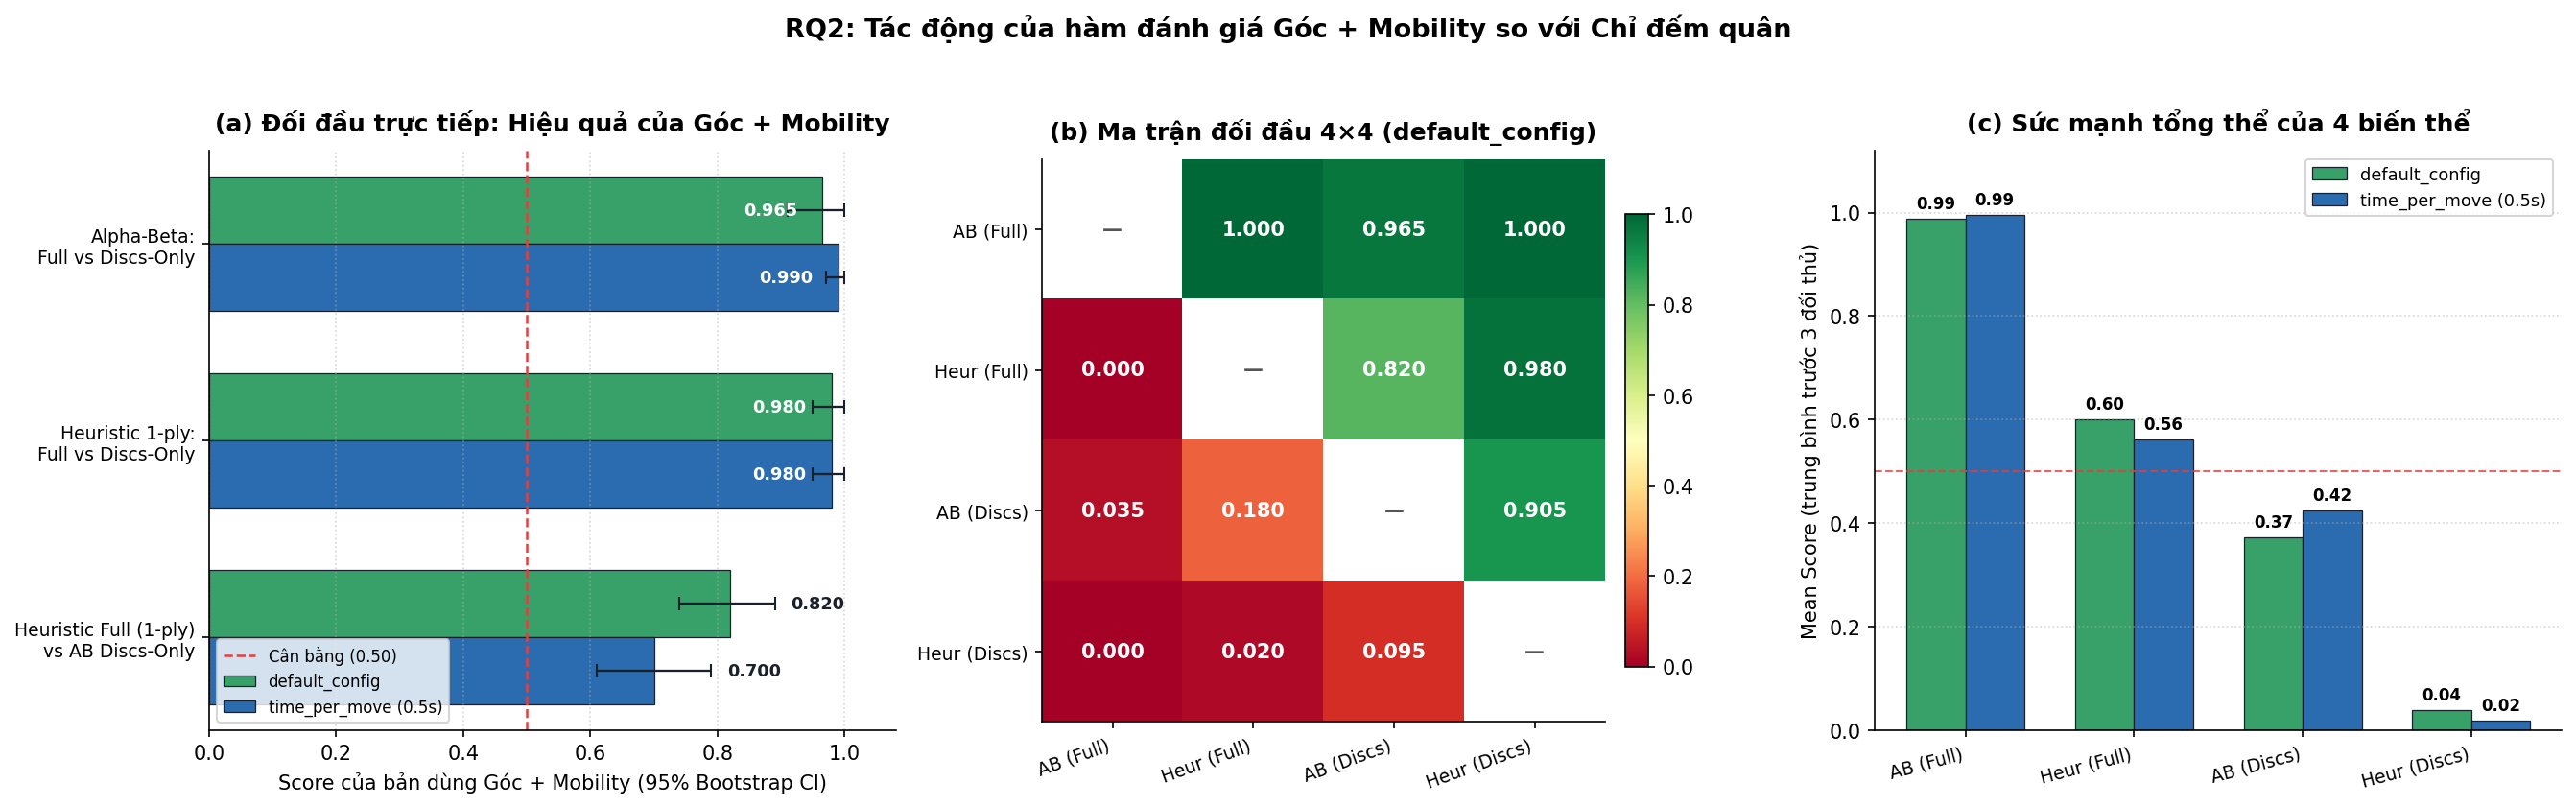

Đã lưu hình: d:\Learn\TTNTNC\Advanced_Artificial_Intelligience_Group\Project_final\results\figures\rq2_eval_corners_mobility_vs_discs.png


In [16]:
# Vẽ biểu đồ RQ2 (3 biểu đồ con: Đối đầu trọng tâm | Ma trận 4x4 | Mean Score & Chi phí nút duyệt)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.4), dpi=150)

# --- Panel A: Đối đầu trực tiếp trọng tâm trả lời RQ2 ---
ax = axes[0]
core_pairs = [
    ("alphabeta", "alphabeta_discs_only", "Alpha-Beta:\nFull vs Discs-Only"),
    ("heuristic", "heuristic_discs_only", "Heuristic 1-ply:\nFull vs Discs-Only"),
    ("heuristic", "alphabeta_discs_only", "Heuristic Full (1-ply)\nvs AB Discs-Only"),
]
y = np.arange(len(core_pairs))
h = 0.34
for idx, (mode_name, col, lbl) in enumerate([
    ("default_config", "#38a169", "default_config"),
    ("time_per_move", "#2b6cb0", "time_per_move (0.5s)"),
]):
    sub = df_rq2_pairs[df_rq2_pairs["Mode"] == mode_name]
    vals, elos, ehis = [], [], []
    for a_k, b_k, _ in core_pairs:
        r = sub[(sub["a"] == a_k) & (sub["b"] == b_k)].iloc[0]
        vals.append(r["Score A"])
        elos.append(max(0.0, r["Score A"] - r["ci_lo"]))
        ehis.append(max(0.0, r["ci_hi"] - r["Score A"]))
    pos = y + (idx - 0.5) * h
    bars = ax.barh(pos, vals, h, label=lbl, color=col, edgecolor="#1a202c", lw=0.6)
    ax.errorbar(vals, pos, xerr=[elos, ehis], fmt="none", ecolor="#1a202c", capsize=3.5, lw=1.1)
    for b, v, eh in zip(bars, vals, ehis):
        if v > 0.88:
            ax.text(v - 0.04, b.get_y() + b.get_height()/2, f"{v:.3f}",
                    va="center", ha="right", fontsize=8.5, fontweight="bold", color="white")
        else:
            ax.text(v + eh + 0.025, b.get_y() + b.get_height()/2, f"{v:.3f}",
                    va="center", ha="left", fontsize=8.5, fontweight="bold", color="#1a202c")

ax.axvline(0.5, color="#e53e3e", linestyle="--", lw=1.2, label="Cân bằng (0.50)")
ax.set_yticks(y, [p[2] for p in core_pairs], fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, 1.08)
ax.set_xlabel("Score của bản dùng Góc + Mobility (95% Bootstrap CI)")
ax.set_title("(a) Đối đầu trực tiếp: Hiệu quả của Góc + Mobility", fontweight="bold", pad=10)
ax.legend(loc="lower left", fontsize=8)
ax.grid(axis="x", linestyle=":", alpha=0.5)

# --- Panel B: Ma trận đối đầu 4x4 (default_config) ---
ax = axes[1]
mdata_def = abl_heur["modes"]["default_config"]
mat = np.full((len(H_ORDER), len(H_ORDER)), np.nan)
for i, ra in enumerate(H_ORDER):
    for j, ca in enumerate(H_ORDER):
        if i != j:
            mat[i, j] = mdata_def["score_matrix"][ra][ca]
im = ax.imshow(mat, cmap="RdYlGn", vmin=0.0, vmax=1.0)
short_h = ["AB (Full)", "Heur (Full)", "AB (Discs)", "Heur (Discs)"]
ax.set_xticks(range(len(H_ORDER)), short_h, rotation=20, ha="right", fontsize=9)
ax.set_yticks(range(len(H_ORDER)), short_h, fontsize=9)
ax.set_title("(b) Ma trận đối đầu 4×4 (default_config)", fontweight="bold", pad=10)
for i in range(len(H_ORDER)):
    for j in range(len(H_ORDER)):
        if i == j:
            ax.text(j, i, "—", ha="center", va="center", fontweight="bold", color="#555")
        else:
            v = mat[i, j]
            ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontweight="bold",
                    color="white" if (v < 0.22 or v > 0.80) else "black")
fig.colorbar(im, ax=ax, shrink=0.78, pad=0.03)

# --- Panel C: Mean Score toàn bảng & Chi phí nút duyệt (time_per_move) ---
ax = axes[2]
x = np.arange(len(H_ORDER))
w = 0.35
s_def = df_rq2_mean["Mean Score (default_config)"].values
s_tpm = df_rq2_mean["Mean Score (time_per_move)"].values
b1 = ax.bar(x - w/2, s_def, w, label="default_config", color="#38a169", edgecolor="#1a202c", lw=0.6)
b2 = ax.bar(x + w/2, s_tpm, w, label="time_per_move (0.5s)", color="#2b6cb0", edgecolor="#1a202c", lw=0.6)
for b in list(b1) + list(b2):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.02, f"{b.get_height():.2f}",
            ha="center", fontsize=8, fontweight="bold")
ax.axhline(0.5, color="#e53e3e", linestyle="--", lw=1.0, alpha=0.8)
ax.set_xticks(x, short_h, rotation=15, ha="right", fontsize=9)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Mean Score (trung bình trước 3 đối thủ)")
ax.set_title("(c) Sức mạnh tổng thể của 4 biến thể", fontweight="bold", pad=10)
ax.legend(fontsize=8.5, loc="upper right")
ax.grid(axis="y", linestyle=":", alpha=0.5)

fig.suptitle("RQ2: Tác động của hàm đánh giá Góc + Mobility so với Chỉ đếm quân",
             fontsize=13, fontweight="bold", y=1.03)
fig.tight_layout()
fig.savefig(FIGS / "rq2_eval_corners_mobility_vs_discs.png", bbox_inches="tight")
plt.show()
print("Đã lưu hình:", FIGS / "rq2_eval_corners_mobility_vs_discs.png")

---
## 3. RQ3 — RL Self-Play vs NN Supervised từ dữ liệu Expert

> **RQ3.** *Tác tử Reinforcement Learning sử dụng phương pháp self-play có cải thiện hiệu quả thi đấu so với tác tử Neural Network được huấn luyện bằng phương pháp supervised learning từ dữ liệu của expert hay không?*

Đánh giá đa chiều từ giải đấu chính:
1. **Đối đầu trực tiếp `RL Self-Play` vs `NN Supervised`** (tổng thể + phân tách cầm Đen/Trắng + kiểm định thống kê $H_0: 	ext{Score} = 0.50$).
2. **Hiệu suất trước từng đối thủ chung** (`Random`, `Heuristic`, `Alpha-Beta`, `MCTS`, và `MCTS-leaf` nếu có) để xem RL cải thiện ở nhóm đối thủ nào.
3. **Điểm trung bình toàn giải (`Mean Score`) & Độ trễ suy luận (`ms/nước`)** của hai mô hình mạng nơ-ron.

In [17]:
# 3.1 Đối đầu trực tiếp RL Self-Play vs NN Supervised
rq3_direct_rows = []
for mode_name, mode_data in tourn["modes"].items():
    rec = get_pair_record(mode_data, "rl", "nn")
    pval = two_sided_z_pvalue(rec["score"], rec["games"])
    sig = "Có (p < 0.05)" if pval < 0.05 else "Chưa đủ bằng chứng (p ≥ 0.05)"
    rq3_direct_rows.append({
        "Chế độ": mode_name,
        "W - D - L (RL vs NN)": f"{rec['wins']} - {rec['draws']} - {rec['losses']}",
        "Score RL": round(rec["score"], 4),
        "Score NN": round(1.0 - rec["score"], 4),
        "Wilson 95% CI (RL)": f"[{rec['wilson_ci'][0]:.3f}, {rec['wilson_ci'][1]:.3f}]",
        "Bootstrap 95% CI (RL)": f"[{rec['boot_ci'][0]:.3f}, {rec['boot_ci'][1]:.3f}]",
        "ci_lo": rec["boot_ci"][0], "ci_hi": rec["boot_ci"][1],
        "RL Black": round(rec["score_black"], 3),
        "RL White": round(rec["score_white"], 3),
        "p-value (H0=0.5)": round(pval, 4),
        "Ý nghĩa thống kê": sig,
        "RL Mean (ms)": round(rec["lat_x"]["mean_ms"], 2),
        "NN Mean (ms)": round(rec["lat_y"]["mean_ms"], 2),
    })

df_rq3_direct = pd.DataFrame(rq3_direct_rows)
print("=== BẢNG RQ3a: ĐỐI ĐẦU TRỰC TIẾP RL SELF-PLAY vs NN SUPERVISED ===")
display(df_rq3_direct.drop(columns=["ci_lo", "ci_hi"]))
df_rq3_direct.drop(columns=["ci_lo", "ci_hi"]).to_csv(
    TABLES / "rq3_rl_vs_nn_direct.csv", index=False, encoding="utf-8-sig"
)

# 3.2 So sánh RL vs NN trước từng đối thủ chung & Mean Score toàn giải
common_opps = [a for a in tourn["config"]["agents"] if a not in ("nn", "rl")]
rq3_opp_rows = []
for mode_name, mode_data in tourn["modes"].items():
    sm = mode_data["score_matrix"]
    for opp in common_opps:
        sc_nn = sm["nn"][opp]
        sc_rl = sm["rl"][opp]
        rq3_opp_rows.append({
            "Chế độ": mode_name,
            "Đối thủ": LABELS.get(opp, opp),
            "opp_key": opp,
            "Score NN": round(sc_nn, 4),
            "Score RL": round(sc_rl, 4),
            "Chênh lệch (RL - NN)": round(sc_rl - sc_nn, 4),
        })
    ms_nn = mode_data["mean_score"]["nn"]
    ms_rl = mode_data["mean_score"]["rl"]
    rq3_opp_rows.append({
        "Chế độ": mode_name,
        "Đối thủ": "TỔNG THỂ (Mean Score)",
        "opp_key": "mean_all",
        "Score NN": round(ms_nn, 4),
        "Score RL": round(ms_rl, 4),
        "Chênh lệch (RL - NN)": round(ms_rl - ms_nn, 4),
    })

df_rq3_opp = pd.DataFrame(rq3_opp_rows)
print("\n=== BẢNG RQ3b: SO SÁNH RL vs NN TRƯỚC TỪNG ĐỐI THỦ CHUNG & TOÀN GIẢI ===")
display(df_rq3_opp.drop(columns=["opp_key"]))
df_rq3_opp.drop(columns=["opp_key"]).to_csv(TABLES / "rq3_rl_vs_nn_by_opponent.csv", index=False, encoding="utf-8-sig")

=== BẢNG RQ3a: ĐỐI ĐẦU TRỰC TIẾP RL SELF-PLAY vs NN SUPERVISED ===


,Chế độ,W - D - L (RL vs NN),Score RL,Score NN,Wilson 95% CI (RL),Bootstrap 95% CI (RL),RL Black,RL White,p-value (H0=0.5),Ý nghĩa thống kê,RL Mean (ms),NN Mean (ms)
0,time_per_move,87 - 9 - 104,0.4575,0.5425,"[0.390, 0.527]","[0.392, 0.523]",0.38,0.535,0.2293,Chưa đủ bằng chứng (p ≥ 0.05),3.55,3.55
1,default_config,87 - 9 - 104,0.4575,0.5425,"[0.390, 0.527]","[0.392, 0.523]",0.38,0.535,0.2293,Chưa đủ bằng chứng (p ≥ 0.05),11.32,11.34



=== BẢNG RQ3b: SO SÁNH RL vs NN TRƯỚC TỪNG ĐỐI THỦ CHUNG & TOÀN GIẢI ===


,Chế độ,Đối thủ,Score NN,Score RL,Chênh lệch (RL - NN)
0,time_per_move,Random (C1),0.9800,0.9900,0.0100
1,time_per_move,Heuristic (C2),0.6825,0.7900,0.1075
2,time_per_move,Alpha-Beta (C3),0.0200,0.0450,0.0250
3,time_per_move,MCTS (C4),0.5400,0.5800,0.0400
4,time_per_move,MCTS-leaf (C4b),0.1475,0.0975,-0.0500
5,time_per_move,TỔNG THỂ (Mean Score),0.4854,0.4933,0.0079
6,default_config,Random (C1),0.9800,0.9900,0.0100
7,default_config,Heuristic (C2),0.6825,0.7900,0.1075
8,default_config,Alpha-Beta (C3),0.1300,0.1850,0.0550
9,default_config,MCTS (C4),0.5500,0.5275,-0.0225


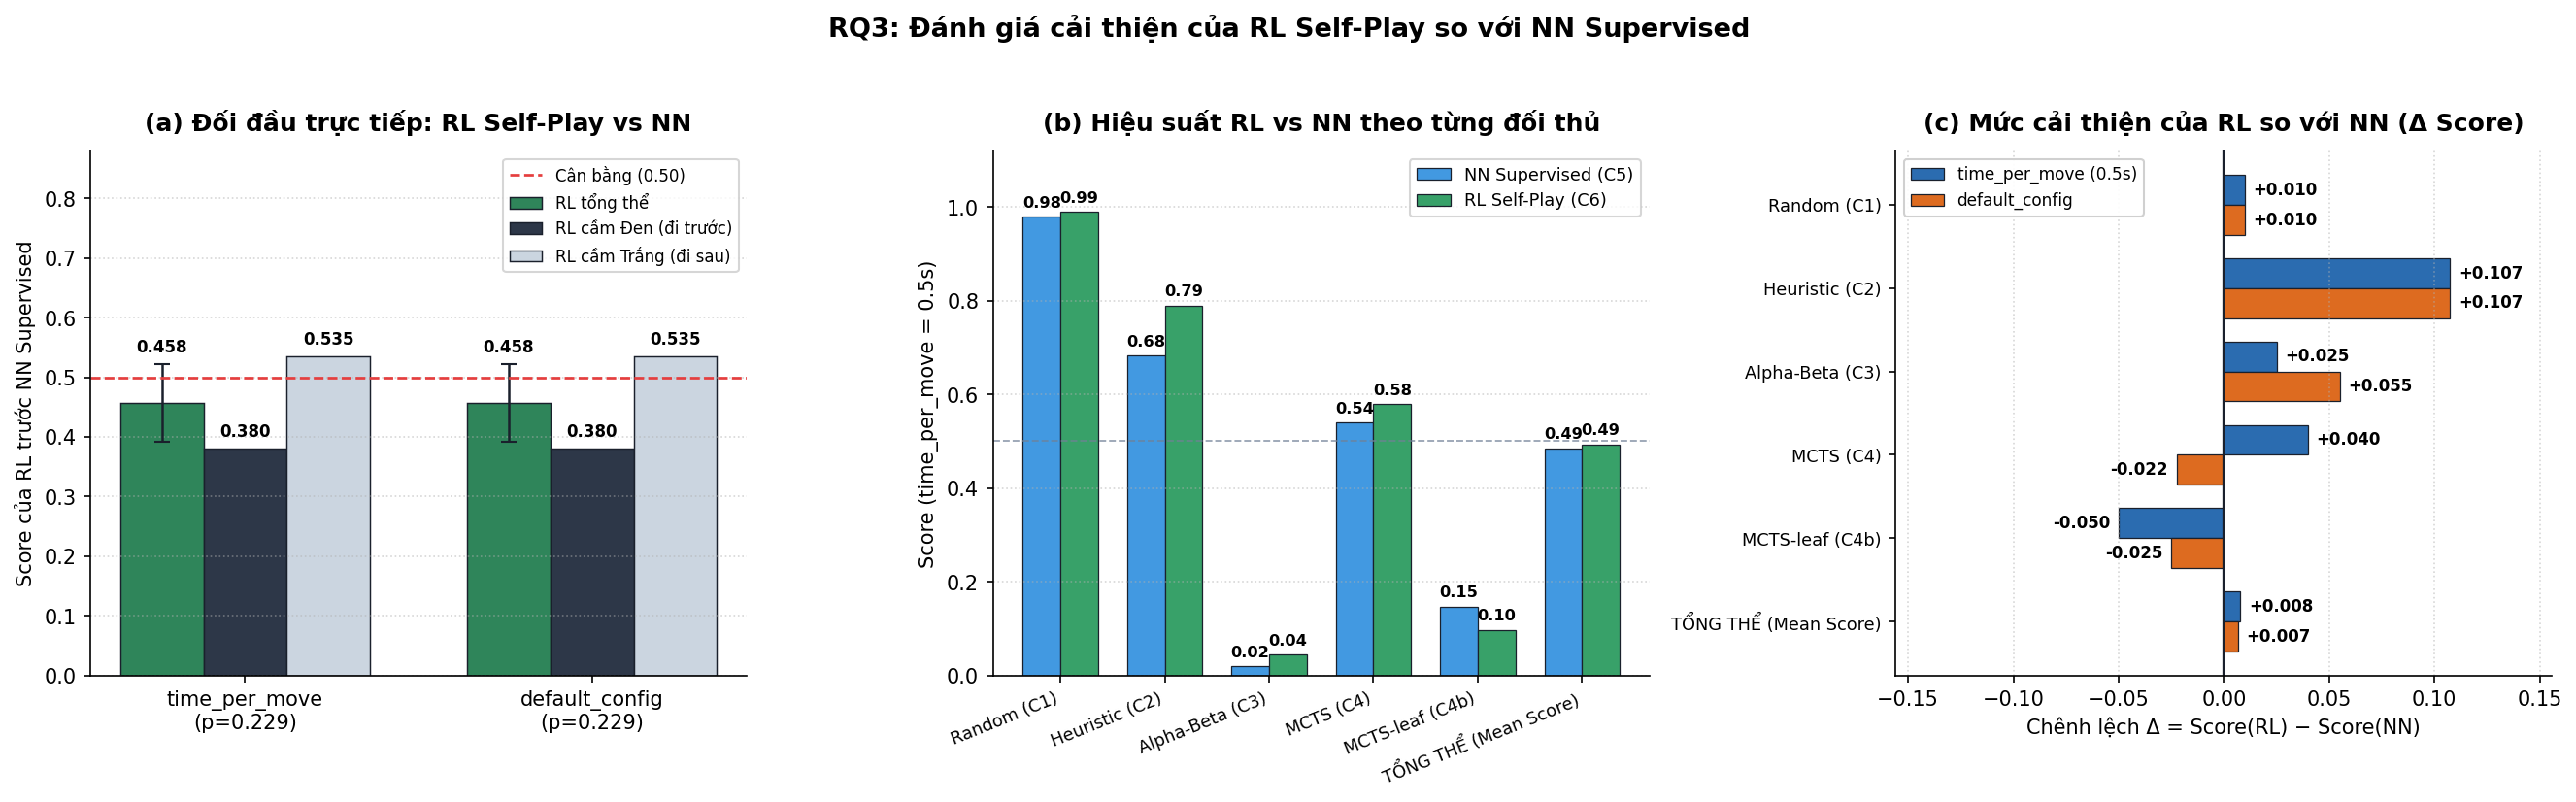

Đã lưu hình: d:\Learn\TTNTNC\Advanced_Artificial_Intelligience_Group\Project_final\results\figures\rq3_rl_vs_nn.png


In [18]:
# Vẽ biểu đồ RQ3 (3 biểu đồ con: Đối đầu trực tiếp theo màu | Điểm theo từng đối thủ | Chênh lệch RL - NN)
fig, axes = plt.subplots(1, 3, figsize=(17.8, 5.3), dpi=150)

# --- Panel A: Đối đầu trực tiếp RL vs NN (tổng thể + tách Đen/Trắng) ---
ax = axes[0]
modes_list = list(df_rq3_direct["Chế độ"])
x = np.arange(len(modes_list))
w = 0.24
b_all = ax.bar(x - w, df_rq3_direct["Score RL"], w, label="RL tổng thể", color="#2f855a", edgecolor="#1a202c", lw=0.7)
b_blk = ax.bar(x, df_rq3_direct["RL Black"], w, label="RL cầm Đen (đi trước)", color="#2d3748", edgecolor="#1a202c", lw=0.7)
b_wht = ax.bar(x + w, df_rq3_direct["RL White"], w, label="RL cầm Trắng (đi sau)", color="#cbd5e0", edgecolor="#1a202c", lw=0.7)
ax.errorbar(x - w, df_rq3_direct["Score RL"],
            yerr=[df_rq3_direct["Score RL"] - df_rq3_direct["ci_lo"], df_rq3_direct["ci_hi"] - df_rq3_direct["Score RL"]],
            fmt="none", ecolor="#1a202c", capsize=4, lw=1.2)
ax.axhline(0.5, color="#e53e3e", linestyle="--", lw=1.3, label="Cân bằng (0.50)")
for b, hi_v in zip(b_all, df_rq3_direct["ci_hi"]):
    ax.text(b.get_x() + b.get_width()/2, hi_v + 0.02, f"{b.get_height():.3f}",
            ha="center", fontsize=8, fontweight="bold")
for b in list(b_blk) + list(b_wht):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.02, f"{b.get_height():.3f}",
            ha="center", fontsize=8, fontweight="bold")
ax.set_xticks(x, [f"{m}\n(p={p:.3f})" for m, p in zip(modes_list, df_rq3_direct["p-value (H0=0.5)"])])
ax.set_ylim(0, 0.88)
ax.set_ylabel("Score của RL trước NN Supervised")
ax.set_title("(a) Đối đầu trực tiếp: RL Self-Play vs NN", fontweight="bold", pad=10)
ax.legend(fontsize=8, loc="upper right")
ax.grid(axis="y", linestyle=":", alpha=0.5)

# --- Panel B: So sánh Score(RL) vs Score(NN) trước từng đối thủ chung (time_per_move) ---
ax = axes[1]
sub_tpm = df_rq3_opp[df_rq3_opp["Chế độ"] == "time_per_move"].reset_index(drop=True)
x2 = np.arange(len(sub_tpm))
w2 = 0.36
b_nn = ax.bar(x2 - w2/2, sub_tpm["Score NN"], w2, label="NN Supervised (C5)", color="#4299e1", edgecolor="#1a202c", lw=0.6)
b_rl = ax.bar(x2 + w2/2, sub_tpm["Score RL"], w2, label="RL Self-Play (C6)", color="#38a169", edgecolor="#1a202c", lw=0.6)
for b in list(b_nn) + list(b_rl):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.02, f"{b.get_height():.2f}",
            ha="center", fontsize=7.8, fontweight="bold")
ax.axhline(0.5, color="#718096", linestyle="--", lw=0.9, alpha=0.7)
ax.set_xticks(x2, sub_tpm["Đối thủ"], rotation=22, ha="right", fontsize=8.5)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Score (time_per_move = 0.5s)")
ax.set_title("(b) Hiệu suất RL vs NN theo từng đối thủ", fontweight="bold", pad=10)
ax.legend(fontsize=8.5, loc="upper right")
ax.grid(axis="y", linestyle=":", alpha=0.5)

# --- Panel C: Chênh lệch Delta = Score(RL) - Score(NN) ở cả 2 chế độ ---
ax = axes[2]
sub_def = df_rq3_opp[df_rq3_opp["Chế độ"] == "default_config"].reset_index(drop=True)
y3 = np.arange(len(sub_tpm))
h3 = 0.36
d_tpm = sub_tpm["Chênh lệch (RL - NN)"].values
d_def = sub_def["Chênh lệch (RL - NN)"].values
bars_t = ax.barh(y3 - h3/2, d_tpm, h3, label="time_per_move (0.5s)", color="#2b6cb0", edgecolor="#1a202c", lw=0.6)
bars_d = ax.barh(y3 + h3/2, d_def, h3, label="default_config", color="#dd6b20", edgecolor="#1a202c", lw=0.6)
ax.axvline(0.0, color="#1a202c", lw=1.1)
max_abs = max(0.08, float(np.max(np.abs(np.concatenate([d_tpm, d_def])))) * 1.45)
ax.set_xlim(-max_abs, max_abs)
for b, dv in zip(list(bars_t) + list(bars_d), np.concatenate([d_tpm, d_def])):
    offset = 0.004 if dv >= 0 else -0.004
    ha = "left" if dv >= 0 else "right"
    ax.text(dv + offset, b.get_y() + b.get_height()/2, f"{dv:+.3f}", va="center", ha=ha, fontsize=8, fontweight="bold")
ax.set_yticks(y3, sub_tpm["Đối thủ"], fontsize=8.5)
ax.invert_yaxis()
ax.set_xlabel("Chênh lệch Δ = Score(RL) − Score(NN)")
ax.set_title("(c) Mức cải thiện của RL so với NN (Δ Score)", fontweight="bold", pad=10)
ax.legend(fontsize=8.2, loc="upper left", framealpha=0.92)
ax.grid(axis="x", linestyle=":", alpha=0.5)

fig.suptitle("RQ3: Đánh giá cải thiện của RL Self-Play so với NN Supervised",
             fontsize=13, fontweight="bold", y=1.03)
fig.tight_layout()
fig.savefig(FIGS / "rq3_rl_vs_nn.png", bbox_inches="tight")
plt.show()
print("Đã lưu hình:", FIGS / "rq3_rl_vs_nn.png")

---
## 4. Tổng hợp kết luận cho cả 3 Câu hỏi Nghiên cứu (RQ1, RQ2, RQ3)

Cell dưới đây tự động tổng hợp bảng trả lời định lượng cho 3 câu hỏi nghiên cứu (gồm cả `MCTS-leaf` trong RQ1 nếu có log) và xuất 1 biểu đồ tổng quan 3 panel (`rq_summary_overview.png`) để sử dụng trực tiếp trong báo cáo và slide thuyết trình.

,RQ,Nội dung kiểm chứng,Kết quả định lượng chính,Kết luận
0,RQ1,MCTS & MCTS-leaf vs Alpha-Beta (cùng 0.5s/nước & đổi ngân sách),"time_per_move (0.5s): MCTS=0.025 [0.005, 0.045] vs AB=0.975; default_config: MCTS=0.120 vs AB=0.880 | MCTS-leaf vs AB: 0.182 [0.130, 0.238] (0.5s), 0.217 (default)",KHÔNG — Alpha-Beta áp đảo MCTS thuần khi cùng 0.5s/nước; ngay cả biến thể lai MCTS-leaf dù cải thiện rõ rệt so với MCTS thuần nhưng vẫn thua Alpha-Beta (0.182 ở 0.5s; 0.217 ở default).
1,RQ2,Hàm đánh giá Góc + Mobility vs Chỉ đếm quân,"AB Full vs Discs-Only: 0.965 (def), 0.990 (0.5s); Heur Full vs Discs-Only: 0.980",CÓ (cải thiện áp đảo) — Kết hợp Góc + tránh X/C + Mobility tăng Score lên 0.965–0.990; ngay cả Heuristic 1-ply đầy đủ cũng thắng Alpha-Beta chỉ đếm quân.
2,RQ3,RL Self-Play vs NN Supervised (từ expert),"Đối đầu trực tiếp (0.5s): RL=0.458 [0.392, 0.523] (p=0.2293); Mean Score toàn giải: RL=0.4933 vs NN=0.4854 (Δ=+0.0079)","CẢI THIỆN NHẸ NHƯNG CHƯA VƯỢT TRỘI RÕ RỆT — RL nhỉnh hơn NN về Mean Score toàn giải (+0.008 ở 0.5s; +0.007 ở default), nhưng đối đầu trực tiếp nằm trong khoảng cân bằng thống kê (p > 0.05)."


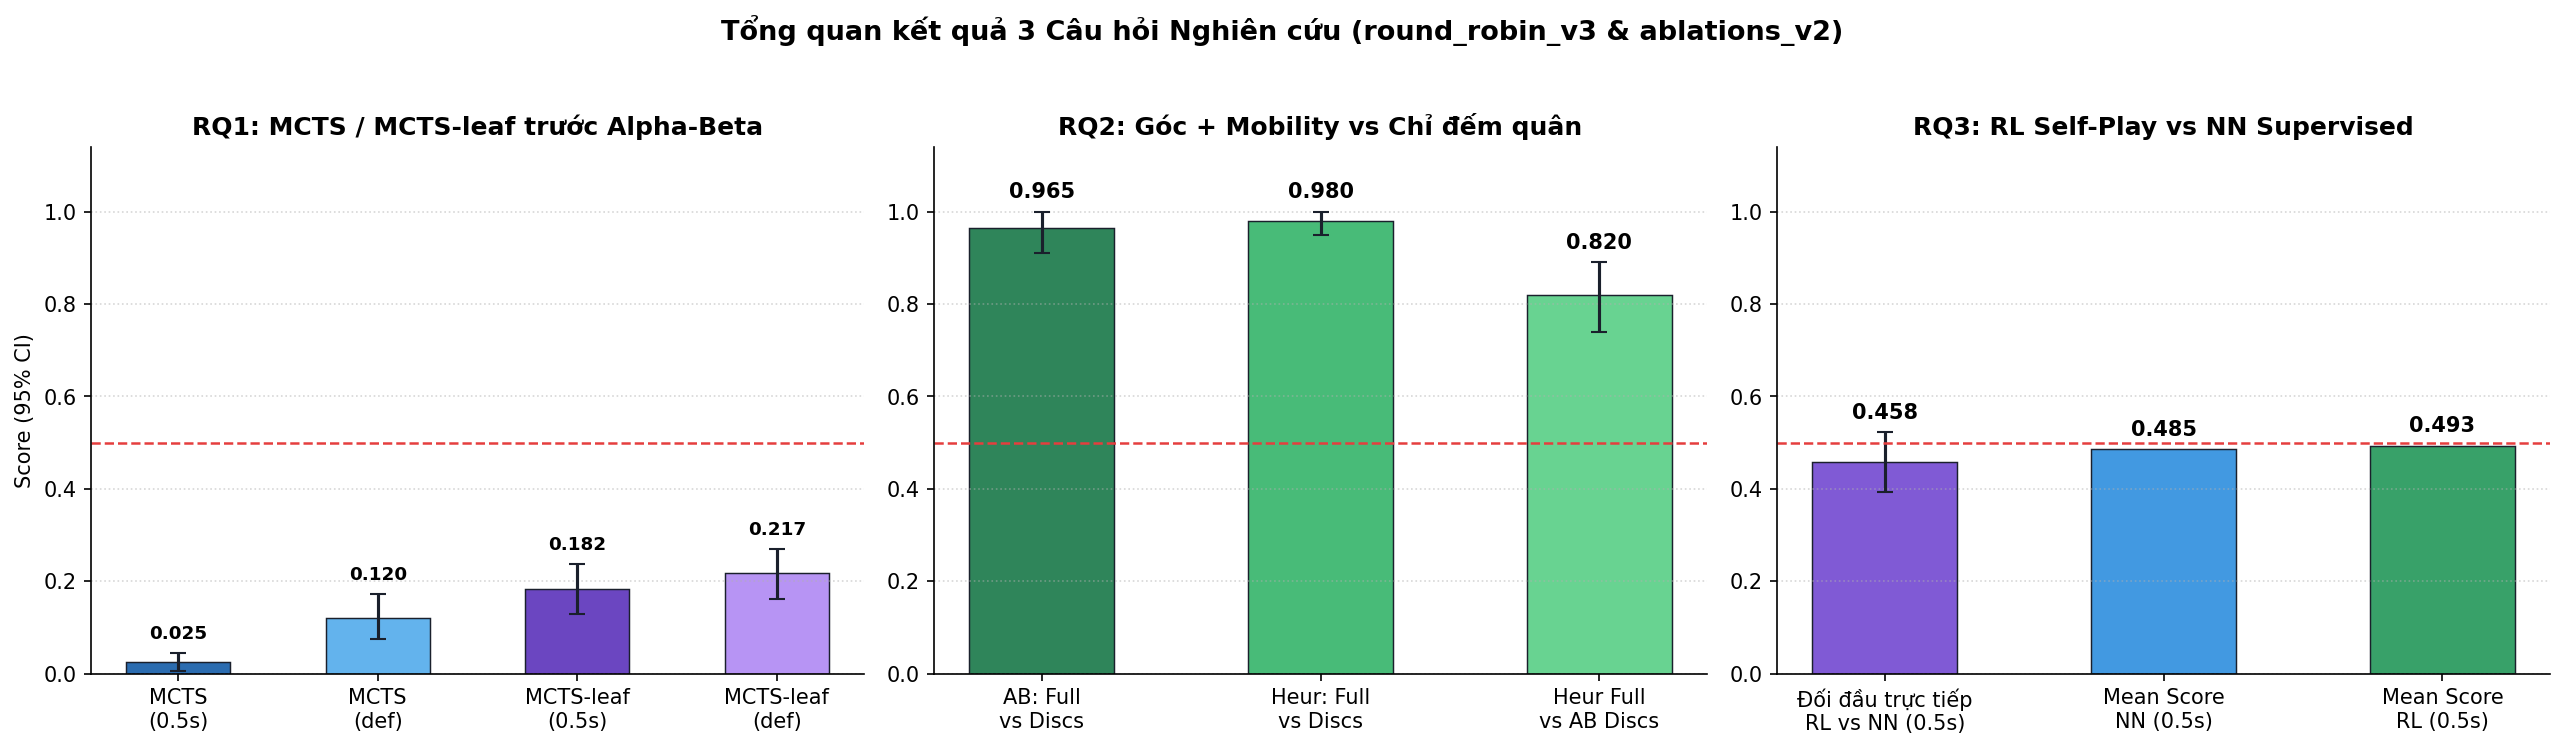

Đã lưu hình tổng quan: d:\Learn\TTNTNC\Advanced_Artificial_Intelligience_Group\Project_final\results\figures\rq_summary_overview.png
Đã lưu các bảng CSV tại: d:\Learn\TTNTNC\Advanced_Artificial_Intelligience_Group\Project_final\results\tables\research_questions


In [19]:
# Trích xuất các con số trọng tâm tự động từ 3 bảng đã phân tích
r1_tpm = df_rq1[(df_rq1["Chế độ"] == "time_per_move") & (df_rq1["mcts_key"] == "mcts")].iloc[0]
r1_def = df_rq1[(df_rq1["Chế độ"] == "default_config") & (df_rq1["mcts_key"] == "mcts")].iloc[0]
has_leaf_row = "mcts_leaf" in df_rq1["mcts_key"].values
r1_lf_tpm = df_rq1[(df_rq1["Chế độ"] == "time_per_move") & (df_rq1["mcts_key"] == "mcts_leaf")].iloc[0] if has_leaf_row else None
r1_lf_def = df_rq1[(df_rq1["Chế độ"] == "default_config") & (df_rq1["mcts_key"] == "mcts_leaf")].iloc[0] if has_leaf_row else None

r2_ab_def = df_rq2_pairs[(df_rq2_pairs["Mode"] == "default_config") & (df_rq2_pairs["a"] == "alphabeta") & (df_rq2_pairs["b"] == "alphabeta_discs_only")].iloc[0]
r2_ab_tpm = df_rq2_pairs[(df_rq2_pairs["Mode"] == "time_per_move") & (df_rq2_pairs["a"] == "alphabeta") & (df_rq2_pairs["b"] == "alphabeta_discs_only")].iloc[0]
r2_h_def = df_rq2_pairs[(df_rq2_pairs["Mode"] == "default_config") & (df_rq2_pairs["a"] == "heuristic") & (df_rq2_pairs["b"] == "heuristic_discs_only")].iloc[0]
r3_tpm = df_rq3_direct[df_rq3_direct["Chế độ"] == "time_per_move"].iloc[0]
r3_mean_tpm = df_rq3_opp[(df_rq3_opp["Chế độ"] == "time_per_move") & (df_rq3_opp["opp_key"] == "mean_all")].iloc[0]
r3_mean_def = df_rq3_opp[(df_rq3_opp["Chế độ"] == "default_config") & (df_rq3_opp["opp_key"] == "mean_all")].iloc[0]

rq1_quant = (
    f"time_per_move (0.5s): MCTS={r1_tpm['Score MCTS']:.3f} {r1_tpm['Bootstrap 95% CI (MCTS)']} vs AB={r1_tpm['Score Alpha-Beta']:.3f}; "
    f"default_config: MCTS={r1_def['Score MCTS']:.3f} vs AB={r1_def['Score Alpha-Beta']:.3f}"
)
if has_leaf_row:
    rq1_quant += (
        f" | MCTS-leaf vs AB: {r1_lf_tpm['Score MCTS']:.3f} {r1_lf_tpm['Bootstrap 95% CI (MCTS)']} (0.5s), "
        f"{r1_lf_def['Score MCTS']:.3f} (default)"
    )

summary_rows = [
    {
        "RQ": "RQ1",
        "Nội dung kiểm chứng": "MCTS & MCTS-leaf vs Alpha-Beta (cùng 0.5s/nước & đổi ngân sách)",
        "Kết quả định lượng chính": rq1_quant,
        "Kết luận": (
            "KHÔNG — Alpha-Beta áp đảo MCTS thuần khi cùng 0.5s/nước; "
            + (
                f"ngay cả biến thể lai MCTS-leaf dù cải thiện rõ rệt so với MCTS thuần nhưng vẫn thua Alpha-Beta ({r1_lf_tpm['Score MCTS']:.3f} ở 0.5s; {r1_lf_def['Score MCTS']:.3f} ở default)."
                if has_leaf_row
                else "khi cấp thêm thời gian cho Alpha-Beta (từ default lên 0.5s), cách biệt nghiêng về Alpha-Beta càng nới rộng."
            )
        ),
    },
    {
        "RQ": "RQ2",
        "Nội dung kiểm chứng": "Hàm đánh giá Góc + Mobility vs Chỉ đếm quân",
        "Kết quả định lượng chính": (
            f"AB Full vs Discs-Only: {r2_ab_def['Score A']:.3f} (def), {r2_ab_tpm['Score A']:.3f} (0.5s); "
            f"Heur Full vs Discs-Only: {r2_h_def['Score A']:.3f}"
        ),
        "Kết luận": (
            "CÓ (cải thiện áp đảo) — Kết hợp Góc + tránh X/C + Mobility tăng Score lên 0.965–0.990; "
            "ngay cả Heuristic 1-ply đầy đủ cũng thắng Alpha-Beta chỉ đếm quân."
        ),
    },
    {
        "RQ": "RQ3",
        "Nội dung kiểm chứng": "RL Self-Play vs NN Supervised (từ expert)",
        "Kết quả định lượng chính": (
            f"Đối đầu trực tiếp (0.5s): RL={r3_tpm['Score RL']:.3f} {r3_tpm['Bootstrap 95% CI (RL)']} (p={r3_tpm['p-value (H0=0.5)']}); "
            f"Mean Score toàn giải: RL={r3_mean_tpm['Score RL']:.4f} vs NN={r3_mean_tpm['Score NN']:.4f} (Δ={r3_mean_tpm['Chênh lệch (RL - NN)']:+.4f})"
        ),
        "Kết luận": (
            "CẢI THIỆN NHẸ NHƯNG CHƯA VƯỢT TRỘI RÕ RỆT — RL nhỉnh hơn NN về Mean Score toàn giải "
            f"({r3_mean_tpm['Chênh lệch (RL - NN)']:+.3f} ở 0.5s; {r3_mean_def['Chênh lệch (RL - NN)']:+.3f} ở default), "
            "nhưng đối đầu trực tiếp nằm trong khoảng cân bằng thống kê (p > 0.05)."
        ),
    },
]

df_rq_summary = pd.DataFrame(summary_rows)
pd.set_option("display.max_colwidth", None)
display(df_rq_summary)
df_rq_summary.to_csv(TABLES / "rq_summary_all.csv", index=False, encoding="utf-8-sig")

# Hình tổng quan 3 panel cho báo cáo & slide
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17.2, 4.8), dpi=150)

# RQ1 overview
if has_leaf_row:
    lbl1 = ["MCTS\n(0.5s)", "MCTS\n(def)", "MCTS-leaf\n(0.5s)", "MCTS-leaf\n(def)"]
    rows1 = [r1_tpm, r1_def, r1_lf_tpm, r1_lf_def]
    cols1 = ["#2b6cb0", "#63b3ed", "#6b46c1", "#b794f4"]
else:
    lbl1 = ["MCTS vs AB\n(0.5s/nước)", "MCTS vs AB\n(default)"]
    rows1 = [r1_tpm, r1_def]
    cols1 = ["#2b6cb0", "#63b3ed"]

v1 = [r["Score MCTS"] for r in rows1]
lo1 = [max(0.0, r["Score MCTS"] - r["ci_lo"]) for r in rows1]
hi1 = [max(0.0, r["ci_hi"] - r["Score MCTS"]) for r in rows1]
b1 = ax1.bar(lbl1, v1, width=0.52, color=cols1, edgecolor="#1a202c", lw=0.7)
ax1.errorbar(lbl1, v1, yerr=[lo1, hi1], fmt="none", ecolor="#1a202c", capsize=4)
ax1.axhline(0.5, color="#e53e3e", ls="--", lw=1.2)
for b, v, eh in zip(b1, v1, hi1):
    ax1.text(b.get_x() + b.get_width()/2, v + eh + 0.03, f"{v:.3f}", ha="center", fontsize=8.8, fontweight="bold")
ax1.set_ylim(0, 1.14); ax1.set_ylabel("Score (95% CI)")
ax1.set_title("RQ1: MCTS / MCTS-leaf trước Alpha-Beta", fontweight="bold")
ax1.grid(axis="y", ls=":", alpha=0.5)

# RQ2 overview
lbl2 = ["AB: Full\nvs Discs", "Heur: Full\nvs Discs", "Heur Full\nvs AB Discs"]
r2_cross = df_rq2_pairs[(df_rq2_pairs["Mode"] == "default_config") & (df_rq2_pairs["a"] == "heuristic") & (df_rq2_pairs["b"] == "alphabeta_discs_only")].iloc[0]
v2 = [r2_ab_def["Score A"], r2_h_def["Score A"], r2_cross["Score A"]]
lo2 = [r2_ab_def["Score A"] - r2_ab_def["ci_lo"], r2_h_def["Score A"] - r2_h_def["ci_lo"], r2_cross["Score A"] - r2_cross["ci_lo"]]
hi2 = [r2_ab_def["ci_hi"] - r2_ab_def["Score A"], r2_h_def["ci_hi"] - r2_h_def["Score A"], r2_cross["ci_hi"] - r2_cross["Score A"]]
b2 = ax2.bar(lbl2, v2, width=0.52, color=["#2f855a", "#48bb78", "#68d391"], edgecolor="#1a202c", lw=0.7)
ax2.errorbar(lbl2, v2, yerr=[lo2, hi2], fmt="none", ecolor="#1a202c", capsize=4)
ax2.axhline(0.5, color="#e53e3e", ls="--", lw=1.2)
for b, v, eh in zip(b2, v2, hi2):
    ax2.text(b.get_x() + b.get_width()/2, v + eh + 0.03, f"{v:.3f}", ha="center", fontweight="bold")
ax2.set_ylim(0, 1.14)
ax2.set_title("RQ2: Góc + Mobility vs Chỉ đếm quân", fontweight="bold")
ax2.grid(axis="y", ls=":", alpha=0.5)

# RQ3 overview
lbl3 = ["Đối đầu trực tiếp\nRL vs NN (0.5s)", "Mean Score\nNN (0.5s)", "Mean Score\nRL (0.5s)"]
v3 = [r3_tpm["Score RL"], r3_mean_tpm["Score NN"], r3_mean_tpm["Score RL"]]
b3 = ax3.bar(lbl3, v3, width=0.52, color=["#805ad5", "#4299e1", "#38a169"], edgecolor="#1a202c", lw=0.7)
ax3.errorbar([lbl3[0]], [v3[0]],
             yerr=[[v3[0] - r3_tpm["ci_lo"]], [r3_tpm["ci_hi"] - v3[0]]],
             fmt="none", ecolor="#1a202c", capsize=4)
ax3.axhline(0.5, color="#e53e3e", ls="--", lw=1.2)
hi3 = [r3_tpm["ci_hi"] - v3[0], 0.0, 0.0]
for b, v, eh in zip(b3, v3, hi3):
    ax3.text(b.get_x() + b.get_width()/2, v + eh + 0.03, f"{v:.3f}", ha="center", fontweight="bold")
ax3.set_ylim(0, 1.14)
ax3.set_title("RQ3: RL Self-Play vs NN Supervised", fontweight="bold")
ax3.grid(axis="y", ls=":", alpha=0.5)

fig.suptitle(f"Tổng quan kết quả 3 Câu hỏi Nghiên cứu ({TOURN_DIR.name} & {ABL_DIR.name})",
             fontsize=13, fontweight="bold", y=1.03)
fig.tight_layout()
fig.savefig(FIGS / "rq_summary_overview.png", bbox_inches="tight")
plt.show()
print("Đã lưu hình tổng quan:", FIGS / "rq_summary_overview.png")
print("Đã lưu các bảng CSV tại:", TABLES)